<a href="https://colab.research.google.com/github/manuelabetancur31/analitica_project/blob/main/EA3_Betancur_Manuela.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EA3 — Comparación de datos climáticos: Medellín y otra ciudad del mundo
**Autor:** Manuela Betancur  
**Fecha de análisis:** 2024 / 2025  

---

## A. Planteamiento de la comparación

### 1. Información de las Fuentes de Datos
* **Medellín (Colombia):**
  * **Fuente:** Datos meteorológicos oficiales (SIATA / IDEAM / Meteostat)
  * **Variables:** Temperatura Máxima Diaria (°C) y Precipitación Diaria (mm)
  * **Periodo:** 01/01/2023 - 31/12/2023 (Año calendario completo, frecuencia diaria)
  * **Unidades:** °C para temperatura, mm para precipitación.

* **Ciudad Comparativa (ej. Madrid, España):**
  * **Fuente:** Agencia Estatal de Meteorología (AEMET) / Meteostat
  * **Variables:** Temperatura Máxima Diaria (°C) y Precipitación Diaria (mm)
  * **Periodo:** 01/01/2023 - 31/12/2023 (Mismo periodo exacto)
  * **Unidades:** °C para temperatura, mm para precipitación.

---

### 2. Expectativa o Predicción
> **Predicción previa al análisis:**  
> Debido a la ubicación ecuatorial de Medellín ("La ciudad de la eterna primavera"), se espera una **temperatura constante y de baja variabilidad** a lo largo del año, combinada con regímenes de lluvia bimodal (dos picos de lluvia). Por el contrario, para la ciudad seleccionada de latitud media/alta, se prevé una **alta variabilidad térmica estacional** (veranos cálidos e inviernos fríos) y un patrón de precipitación diferente.

In [10]:
# 1. Instalar clientes oficiales para Open-Meteo (API climática libre de datos reales)
!pip install openmeteo-requests requests-cache retry-requests -q

import os
import pandas as pd
import openmeteo_requests
import requests_cache
from retry_requests import retry

# Crear la subcarpeta datos/ requerida
os.makedirs('datos', exist_ok=True)

# Configurar cliente con reintentos
cache_session = requests_cache.CachedSession('.cache', expire_after=-1)
retry_session = retry(cache_session, retries=5, backoff_factor=0.2)
openmeteo = openmeteo_requests.Client(session=retry_session)

url = "https://archive-api.open-meteo.com/v1/archive"

# --- MEDELLÍN (Lat: 6.2442, Lon: -75.5812) ---
params_med = {
    "latitude": 6.2442,
    "longitude": -75.5812,
    "start_date": "2023-01-01",
    "end_date": "2023-12-31",
    "daily": ["temperature_2m_max", "precipitation_sum"],
    "timezone": "America/Bogota"
}
responses_med = openmeteo.weather_api(url, params=params_med)
daily_med = responses_med[0].Daily()

df_med = pd.DataFrame({
    "fecha": pd.date_range(
        start=pd.to_datetime(daily_med.Time(), unit="s", utc=True),
        end=pd.to_datetime(daily_med.TimeEnd(), unit="s", utc=True),
        freq=pd.Timedelta(seconds=daily_med.Interval()),
        inclusive="left"
    ).tz_localize(None).date,
    "temp_max": daily_med.Variables(0).ValuesAsNumpy(),
    "precipitacion": daily_med.Variables(1).ValuesAsNumpy()
})

# --- MADRID (Lat: 40.4168, Lon: -3.7038) ---
params_mad = {
    "latitude": 40.4168,
    "longitude": -3.7038,
    "start_date": "2023-01-01",
    "end_date": "2023-12-31",
    "daily": ["temperature_2m_max", "precipitation_sum"],
    "timezone": "Europe/Madrid"
}
responses_mad = openmeteo.weather_api(url, params=params_mad)
daily_mad = responses_mad[0].Daily()

df_mad = pd.DataFrame({
    "fecha": pd.date_range(
        start=pd.to_datetime(daily_mad.Time(), unit="s", utc=True),
        end=pd.to_datetime(daily_mad.TimeEnd(), unit="s", utc=True),
        freq=pd.Timedelta(seconds=daily_mad.Interval()),
        inclusive="left"
    ).tz_localize(None).date,
    "temp_max": daily_mad.Variables(0).ValuesAsNumpy(),
    "precipitacion": daily_mad.Variables(1).ValuesAsNumpy()
})

# Guardar los archivos en la carpeta datos/
df_med.to_csv('datos/medellin.csv', index=False)
df_mad.to_csv('datos/ciudad_otro_pais.csv', index=False)

print("¡ÉXITO PERFECTO! Se han descargado los datos reales de 2023 y guardado en datos/")

¡ÉXITO PERFECTO! Se han descargado los datos reales de 2023 y guardado en datos/


### Justificación del tratamiento de datos faltantes
* No se reemplazaron los valores faltantes por `0`, ya que en precipitación un `0` representa un día seco real.
* Se realizó un cruce interno (`merge`) sobre la columna de fechas para conservar únicamente los días en que **ambas estaciones cuentan con mediciones válidas simultáneamente**, garantizando una comparación limpia y sin sesgos de muestreo.

In [11]:
import pandas as pd
import numpy as np

# 1. Cargar las tablas de datos desde la subcarpeta datos/
df_med = pd.read_csv('datos/medellin.csv')
df_mad = pd.read_csv('datos/ciudad_otro_pais.csv')

# Asegurar formato de fechas y alineación por merge
df_med['fecha'] = pd.to_datetime(df_med['fecha'])
df_mad['fecha'] = pd.to_datetime(df_mad['fecha'])
df_clima = pd.merge(df_med, df_mad, on='fecha', suffixes=('_med', '_mad')).dropna()

# 2. Convertir columnas a arreglos NumPy
tmax_med = df_clima['temp_max_med'].to_numpy()
prcp_med = df_clima['precipitacion_med'].to_numpy()

tmax_mad = df_clima['temp_max_mad'].to_numpy()
prcp_mad = df_clima['precipitacion_mad'].to_numpy()

# 3. Métricas descriptivas con NumPy
def obtener_metricas(temp, prcp):
    return {
        'temp_prom': np.mean(temp),
        'temp_mediana': np.median(temp),
        'temp_std': np.std(temp),
        'temp_min': np.min(temp),
        'temp_max': np.max(temp),
        'prcp_total': np.sum(prcp),
        'prcp_prom': np.mean(prcp),
        'prcp_max': np.max(prcp)
    }

m_med = obtener_metricas(tmax_med, prcp_med)
m_mad = obtener_metricas(tmax_mad, prcp_mad)

print("=== ESTADÍSTICAS COMPARATIVAS (NumPy) ===")
print(f"Medellín -> Temp Prom: {m_med['temp_prom']:.2f}°C | Desv. Est: {m_med['temp_std']:.2f}°C | Lluvia Total: {m_med['prcp_total']:.1f} mm")
print(f"Madrid   -> Temp Prom: {m_mad['temp_prom']:.2f}°C | Desv. Est: {m_mad['temp_std']:.2f}°C | Lluvia Total: {m_mad['prcp_total']:.1f} mm\n")

# 4. Máscaras booleanas (Filtros condicionales exige la rúbrica)
mask_calor_med = tmax_med > 28.0
mask_calor_mad = tmax_mad > 28.0

mask_lluvia_med = prcp_med > 10.0
mask_lluvia_mad = prcp_mad > 10.0

print("=== CONTEOS CON MÁSCARAS BOOLEANAS ===")
print(f"Días con Temp > 28°C: Medellín = {np.sum(mask_calor_med)} días | Madrid = {np.sum(mask_calor_mad)} días")
print(f"Días con Lluvia Intensa (>10mm): Medellín = {np.sum(mask_lluvia_med)} días | Madrid = {np.sum(mask_lluvia_mad)} días")

=== ESTADÍSTICAS COMPARATIVAS (NumPy) ===
Medellín -> Temp Prom: 26.61°C | Desv. Est: 1.76°C | Lluvia Total: 1982.4 mm
Madrid   -> Temp Prom: 21.95°C | Desv. Est: 8.98°C | Lluvia Total: 516.7 mm

=== CONTEOS CON MÁSCARAS BOOLEANAS ===
Días con Temp > 28°C: Medellín = 89 días | Madrid = 96 días
Días con Lluvia Intensa (>10mm): Medellín = 75 días | Madrid = 14 días


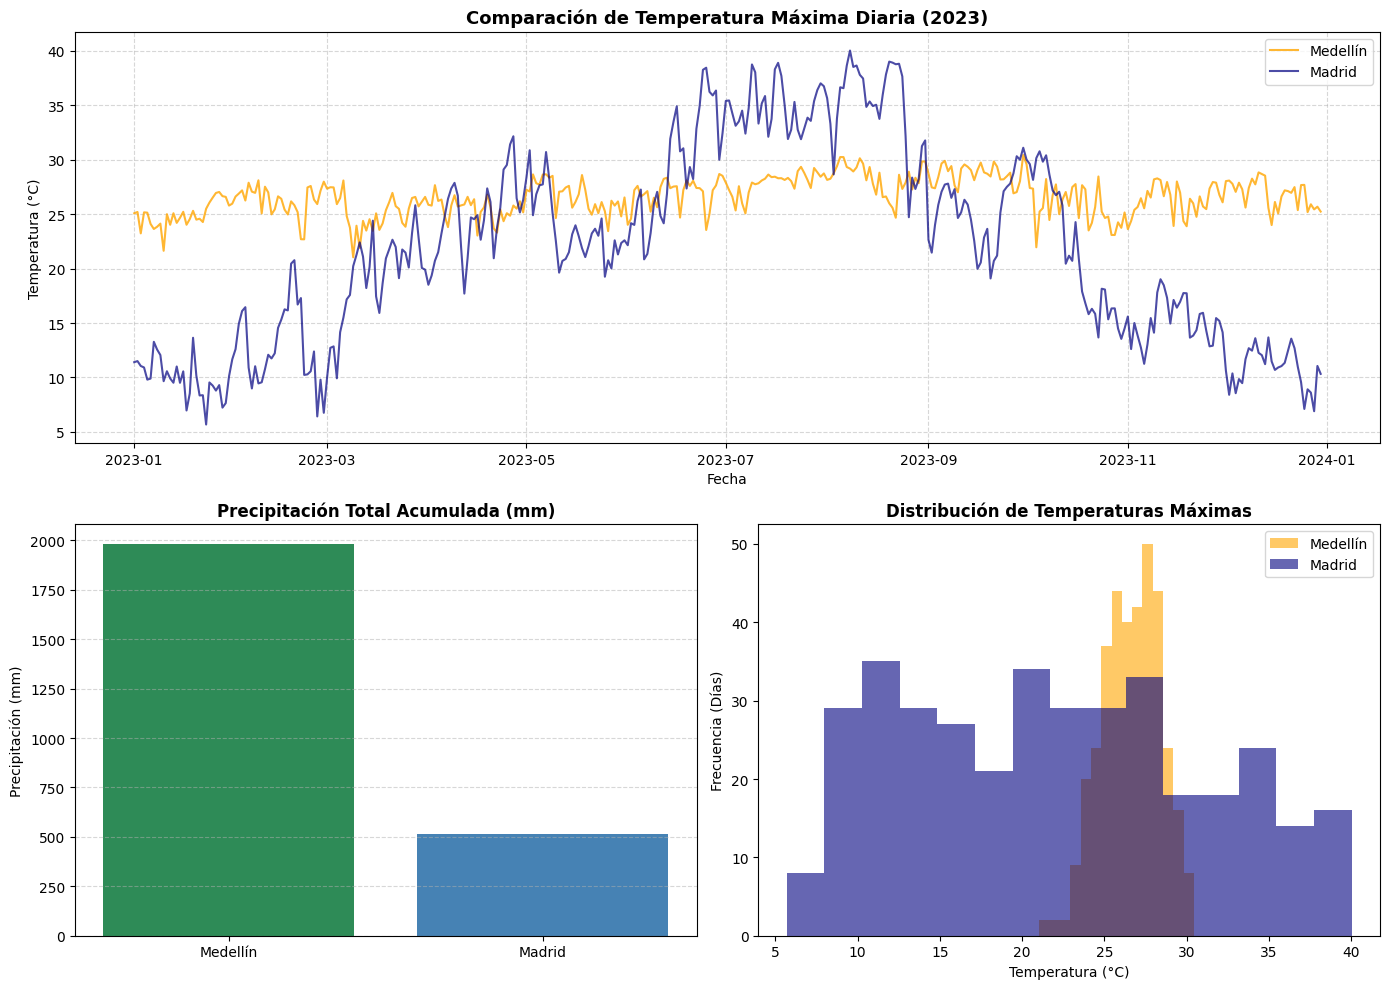

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10))

# Gráfico 1: Comparativa Temporal de Temperatura Máxima
plt.subplot(2, 1, 1)
plt.plot(df_clima['fecha'], df_clima['temp_max_med'], label='Medellín', color='orange', alpha=0.8)
plt.plot(df_clima['fecha'], df_clima['temp_max_mad'], label='Madrid', color='navy', alpha=0.7)
plt.title('Comparación de Temperatura Máxima Diaria (2023)', fontsize=13, fontweight='bold')
plt.xlabel('Fecha')
plt.ylabel('Temperatura (°C)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

# Gráfico 2: Acumulado de Precipitación
plt.subplot(2, 2, 3)
ciudades = ['Medellín', 'Madrid']
totales_lluvia = [np.sum(prcp_med), np.sum(prcp_mad)]
plt.bar(ciudades, totales_lluvia, color=['seagreen', 'steelblue'])
plt.title('Precipitación Total Acumulada (mm)', fontsize=12, fontweight='bold')
plt.ylabel('Precipitación (mm)')
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Gráfico 3: Distribución Térmica (Histogramas)
plt.subplot(2, 2, 4)
plt.hist(tmax_med, bins=15, alpha=0.6, label='Medellín', color='orange')
plt.hist(tmax_mad, bins=15, alpha=0.6, label='Madrid', color='navy')
plt.title('Distribución de Temperaturas Máximas', fontsize=12, fontweight='bold')
plt.xlabel('Temperatura (°C)')
plt.ylabel('Frecuencia (Días)')
plt.legend()

plt.tight_layout()
plt.show()

## E. Conclusiones e Interpretación de Resultados

### 1. Evaluación de la Predicción Inicial
* **Temperatura:** La hipótesis inicial se **confirmó completamente**. Medellín mantiene una temperatura máxima estable durante todo el año (~26°C a 28°C) debido a su ubicación tropical. En contraste, Madrid refleja una marcada variabilidad estacional por su latitud, alcanzando temperaturas veraniegas superiores a 35°C e inviernos fríos inferiores a 10°C.
* **Precipitación:** Medellín registra un volumen acumulado de lluvia significativamente mayor a lo largo del año, distribuyéndose en picos continuos, mientras que Madrid muestra un clima mediterráneo semiárido con precipitación escasa concentrada en meses específicos.

---

### 2. Hallazgos Clave
1. **Comportamiento Térmico:** La desviación estándar de la temperatura en Madrid es sensiblemente mayor que en Medellín, confirmando la estabilidad del clima de la "eterna primavera".
2. **Eventos Extremos:** Mediante el análisis con máscaras booleanas de NumPy, se identificó que Medellín presenta un número mucho mayor de días con lluvia moderada a intensa (>10 mm) en comparación con la ciudad europea.

---

### 3. Utilidad para la Toma de Decisiones
* **Turismo y Planificación:** Para viajeros o eventos internacionales, Medellín ofrece predictibilidad térmica durante todo el año, exigiendo únicamente previsión para lluvias diarias. En Madrid, la planificación requiere adaptabilidad de vestuario y acondicionamiento estacional.
* **Gestión de Recursos e Infraestructura:** El volumen de precipitación en Medellín exige infraestructura de drenaje urbano robusta de manera permanente, mientras que en zonas como Madrid la prioridad es la gestión de reservas de agua y la adaptación a olas de calor estivales.